# Лабораторная работа № 2.2
## Статистические оценки параметров распределения

**Выполнили:**

- Левченков Артемий Викторович;
- Бикбулатова Динара Фануровна;
- Ладыгин Максим Александрович.

**Группа:** БИВТ-24-АЭ-3

**Цель работы:** получить точечные оценки параметров нормального распределения методом моментов, выполнить выравнивание интервального ряда и построить доверительный интервал для математического ожидания возраста при неизвестном СКО.

**Исходные данные:** статистика возрастов людей, совершивших преступления в Москве в 2021 году.

### 1. Подготовка данных и выборок

Объём повторной выборки определяется по формулам

$$
\bar x=\frac{\sum x_i n_i}{\sum n_i},\qquad
\sigma=\sqrt{\frac{\sum (x_i-\bar x)^2n_i}{\sum n_i}},\qquad
n=\left\lceil\frac{t^2\sigma^2}{\delta^2}\right\rceil.
$$

Принимаются $\gamma=0{,}95$ и $\delta=3$ года. Коэффициент $t$ определяется как квантиль стандартного нормального распределения:

$$t=F^{-1}\left(\frac{1+\gamma}{2}\right).$$

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, floor, sqrt, exp, pi
from statistics import NormalDist
from scipy import stats

data = pd.read_table("/Users/blx000/PycharmProjects/matstat/data/moscow.txt", header=None)[0]
N = len(data)

print("Количество наблюдений:", N)
print("Минимальный возраст:", data.min())
print("Максимальный возраст:", data.max())

Количество наблюдений: 32423
Минимальный возраст: 14
Максимальный возраст: 73


In [11]:
discrete = data.value_counts().sort_index().rename_axis("x").reset_index(name="n")
discrete["w"] = discrete["n"] / N

print("Дискретный ряд")
display(discrete)

def mean_value(x, n):
    return sum(x * n) / sum(n)

def dispersion(x, n, mean):
    return sum((x - mean) ** 2 * n) / sum(n)

def standard_deviation(D):
    return D ** 0.5

def minimum(x):
    return min(x)

def maximum(x):
    return max(x)

x = discrete["x"]
n = discrete["n"]

mean_d = mean_value(x, n)
D_d = dispersion(x, n, mean_d)
sigma_d = standard_deviation(D_d)

print(f"Средняя: {mean_d:.4f}")
print(f"Дисперсия: {D_d:.4f}")
print(f"Среднее квадратическое отклонение: {sigma_d:.4f}")

gamma = 0.95
delta = 3
t = NormalDist().inv_cdf((1 + gamma) / 2)

n_exact = t ** 2 * sigma_d ** 2 / delta ** 2
sample_size = ceil(n_exact)
number_of_samples = 36

print(f"Надёжность: {gamma}")
print(f"Точность: {delta} года")
print(f"Коэффициент доверия: {t}")
print(f"Расчётный объём: {n_exact:.4f}")
print(f"Объём каждой выборки: {sample_size}")
print(f"Количество повторных выборок: {number_of_samples}")

Дискретный ряд


,x,n,w
0,14,49,0.001511
1,15,53,0.001635
2,16,236,0.007279
3,17,126,0.003886
4,18,806,0.024859
5,19,971,0.029948
6,20,910,0.028066
7,21,716,0.022083
8,22,944,0.029115
9,23,1071,0.033032


Средняя: 35.3730
Дисперсия: 144.9170
Среднее квадратическое отклонение: 12.0381
Надёжность: 0.95
Точность: 3 года
Коэффициент доверия: 1.9599639845400534
Расчётный объём: 61.8547
Объём каждой выборки: 62
Количество повторных выборок: 36


In [12]:
samples = []
sample_means = []

for i in range(number_of_samples):
    sample = data.sample(n=sample_size, replace=True)
    samples.append(sample)

    sample_discrete = sample.value_counts().sort_index().rename_axis("x").reset_index(name="n")
    sample_discrete["w"] = sample_discrete["n"] / sample_size

    x = sample_discrete["x"]
    n = sample_discrete["n"]
    sample_mean = mean_value(x, n)
    sample_means.append(sample_mean)

sample_means = pd.Series(sample_means)

means_table = pd.DataFrame({
    "Номер выборки": range(1, number_of_samples + 1),
    "Выборочная средняя": sample_means,
})

display(means_table.round(4))

,Номер выборки,Выборочная средняя
0,1,37.7258
1,2,36.3065
2,3,35.4677
3,4,34.9677
4,5,37.0161
5,6,33.7903
6,7,34.4677
7,8,34.8871
8,9,35.0968
9,10,35.0323


### 2. Интервальный ряд выборочных средних

Границы ряда определяются округлением минимального среднего вниз и максимального среднего вверх. Ширина интервала $h=1$ год.

In [13]:
min_mean = minimum(sample_means)
max_mean = maximum(sample_means)
x_min = floor(min_mean)
x_max = ceil(max_mean)

h = 1
k = x_max - x_min
edges = [x_min + i * h for i in range(k + 1)]

rows = []
for i in range(k):
    left = edges[i]
    right = edges[i + 1]

    if i < k - 1:
        n = ((sample_means >= left) & (sample_means < right)).sum()
    else:
        n = ((sample_means >= left) & (sample_means <= right)).sum()

    rows.append([left, right, (left + right) / 2, n])

interval = pd.DataFrame(rows, columns=["x_l", "x_r", "x_middle", "n"])
interval["w"] = interval["n"] / number_of_samples

print(f"Минимальная выборочная средняя: {min_mean:.4f}")
print(f"Максимальная выборочная средняя: {max_mean:.4f}")
print(f"Границы интервального ряда: [{x_min}; {x_max}]")
print(f"Ширина интервала: h = {h}")
display(interval.round(4))
a = interval["n"].sum()
print(f"Сумма абсолютных частот: {a}")
print(f"Сумма относительных частот: {interval['w'].sum():.4f}")

assert a == number_of_samples
assert abs(interval["w"].sum() - 1) < 1e-12

Минимальная выборочная средняя: 32.5484
Максимальная выборочная средняя: 38.2581
Границы интервального ряда: [32; 39]
Ширина интервала: h = 1


,x_l,x_r,x_middle,n,w
0,32,33,32.5,2,0.0556
1,33,34,33.5,4,0.1111
2,34,35,34.5,7,0.1944
3,35,36,35.5,9,0.2500
4,36,37,36.5,6,0.1667
5,37,38,37.5,7,0.1944
6,38,39,38.5,1,0.0278


Сумма абсолютных частот: 36
Сумма относительных частот: 1.0000


### 3. Точечные оценки методом моментов

Для середин интервалов $x_i$ и относительных частот $w_i=n_i/m$ оценки параметров нормального распределения равны

$$
\hat a=\bar x=\sum_{i=1}^{k}x_iw_i,\qquad
\hat D=\sum_{i=1}^{k}(x_i-\bar x)^2w_i,\qquad
\hat\sigma=\sqrt{\hat D}.
$$

Плотность нормального распределения:

$$
f(x)=\frac{1}{\hat\sigma\sqrt{2\pi}}
\exp\left(-\frac{(x-\hat a)^2}{2\hat\sigma^2}\right).
$$

In [14]:
x = interval["x_middle"]
n = interval["n"]

a_est = mean_value(x, n)
D_est = dispersion(x, n, a_est)
sigma_est = standard_deviation(D_est)

if sigma_est == 0:
    raise ValueError("СКО выборочных средних равно нулю: нормальную кривую построить нельзя")

print(f"Оценка математического ожидания â = {a_est:.4f} года")
print(f"Оценка дисперсии D̂ = {D_est:.4f} года²")
print(f"Оценка СКО σ̂ = {sigma_est:.4f} года")

Оценка математического ожидания â = 35.5556 года
Оценка дисперсии D̂ = 2.3302 года²
Оценка СКО σ̂ = 1.5265 года


In [15]:
def normal_density(x, a, sigma):
    return exp(-(x - a) ** 2 / (2 * sigma ** 2)) / (sigma * sqrt(2 * pi))

interval["f(x_middle)"] = [normal_density(x, a_est, sigma_est) for x in interval["x_middle"]]
interval["n_theory"] = number_of_samples * h * interval["f(x_middle)"]

print("Теоретические частоты по значениям плотности в серединах интервалов:")
display(interval[["x_l", "x_r", "n", "w", "f(x_middle)", "n_theory"]].round(4))

Теоретические частоты по значениям плотности в серединах интервалов:


,x_l,x_r,n,w,f(x_middle),n_theory
0,32,33,2,0.0556,0.0353,1.2691
1,33,34,4,0.1111,0.1056,3.7999
2,34,35,7,0.1944,0.2058,7.4077
3,35,36,9,0.2500,0.2612,9.4021
4,36,37,6,0.1667,0.2158,7.7695
5,37,38,7,0.1944,0.1161,4.1801
6,38,39,1,0.0278,0.0407,1.4642


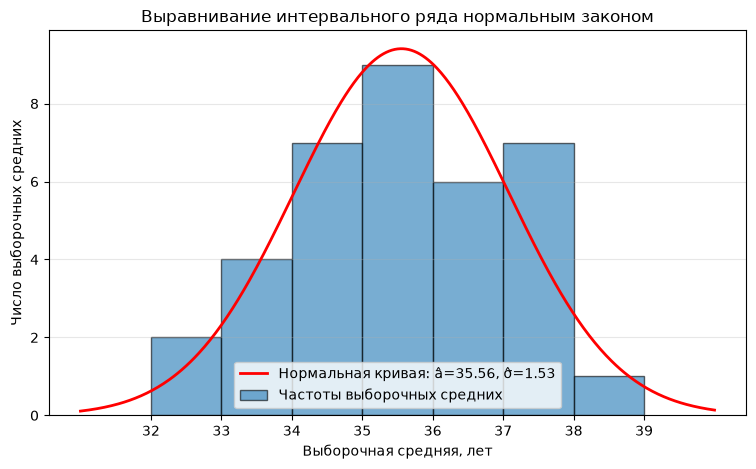

In [16]:
x_curve = [x_min - 1 + i * 0.02 for i in range(int((x_max - x_min + 2) / 0.02) + 1)]
y_curve = [number_of_samples * h * normal_density(x, a_est, sigma_est) for x in x_curve]

plt.figure(figsize=(9, 5))
plt.bar(interval["x_l"], interval["n"], width=h, align="edge", edgecolor="black",
        alpha=0.6, label="Частоты выборочных средних")
plt.plot(x_curve, y_curve, color="red", linewidth=2,
         label=f"Нормальная кривая: â={a_est:.2f}, σ̂={sigma_est:.2f}")
plt.title("Выравнивание интервального ряда нормальным законом")
plt.xlabel("Выборочная средняя, лет")
plt.ylabel("Число выборочных средних")
plt.xticks(edges)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.show()

Для сопоставления с гистограммой частот значения плотности умножены на $m h$, где $m=36$ — число выборочных средних, $h=1$ — ширина интервала.

### 4. Доверительный интервал математического ожидания

Расчёт выполняется по первой сгенерированной выборке. При неизвестном генеральном СКО используются исправленное выборочное СКО и распределение Стьюдента:

$$
\bar x=\frac{1}{n}\sum_{j=1}^{n}x_j,\qquad
s=\sqrt{\frac{\sum_{j=1}^{n}(x_j-\bar x)^2}{n-1}},
$$

$$
t_\gamma=t_{(1+\gamma)/2;\,n-1},\qquad
\delta=\frac{t_\gamma s}{\sqrt n},\qquad
\bar x-\delta<a<\bar x+\delta.
$$

In [17]:
sample_number = 1
one_sample = samples[sample_number - 1]
n_sample = len(one_sample)
x_bar = sum(one_sample) / n_sample
s = sqrt(sum((value - x_bar) ** 2 for value in one_sample) / (n_sample - 1))
degrees_of_freedom = n_sample - 1
t_gamma = stats.t.ppf((1 + gamma) / 2, degrees_of_freedom)
delta_ci = t_gamma * s / sqrt(n_sample)
low = x_bar - delta_ci
high = x_bar + delta_ci

print(f"Выборка №{sample_number}, объём n = {n_sample}")
print(f"Точечная оценка x̄ = {x_bar:.4f} года")
print(f"Исправленное СКО s = {s:.4f} года")
print(f"Число степеней свободы = {degrees_of_freedom}")
print(f"Квантиль Стьюдента t_γ = {t_gamma:.4f}")
print(f"Точность оценки δ = {delta_ci:.4f} года")
print(f"Доверительный интервал: {low:.4f} < a < {high:.4f} года")

assert abs(x_bar - sample_means.iloc[sample_number - 1]) < 1e-12
assert low < x_bar < high

Выборка №1, объём n = 62
Точечная оценка x̄ = 37.7258 года
Исправленное СКО s = 12.8205 года
Число степеней свободы = 61
Квантиль Стьюдента t_γ = 1.9996
Точность оценки δ = 3.2558 года
Доверительный интервал: 34.4700 < a < 40.9816 года


### Вывод

In [18]:
print(f"По {number_of_samples} выборочным средним построен интервальный ряд с шагом {h} год.")
print(f"Точечные оценки параметров: â = {a_est:.4f}, σ̂ = {sigma_est:.4f} года.")
print(f"Для выборки объёма {n_sample} точечная оценка среднего возраста равна {x_bar:.4f} года.")
print(f"При γ = {gamma:.2f} точность оценки составляет {delta_ci:.4f} года.")
print(f"Доверительный интервал математического ожидания: ({low:.4f}; {high:.4f}) года.")

По 36 выборочным средним построен интервальный ряд с шагом 1 год.
Точечные оценки параметров: â = 35.5556, σ̂ = 1.5265 года.
Для выборки объёма 62 точечная оценка среднего возраста равна 37.7258 года.
При γ = 0.95 точность оценки составляет 3.2558 года.
Доверительный интервал математического ожидания: (34.4700; 40.9816) года.
